# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    inputs = tokenizer.apply_chat_template(
        messages,
        tools=tools,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)

    prompt_length = inputs["input_ids"].shape[1]

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.eos_token_id,
        )

    new_token_ids = output_ids[0, prompt_length:]
    return tokenizer.decode(
        new_token_ids,
        skip_special_tokens=True,
    ).strip()

def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Ваш разбор · 2 балла
Ответьте текстом по ячейкам выше:
- **1 балл.** В тексте после шаблона результат функции оказался внутри реплики **user**, а не assistant.
  Почему формат устроен так и что пошло бы не так, если бы модель училась предсказывать содержимое
  `<tool_response>` наравне со своими репликами?
- **1 балл.** По таблице типов сценариев: какой навык function calling даёт каждый из четырёх типов
  и чему модель не научится, если какой-то тип убрать из данных?

**1. Почему результат функции относится к входу.** Сообщение `tool` содержит наблюдение из внешней
среды: его создаёт не языковая модель, а симулятор после исполнения вызова. Qwen представляет такие
наблюдения как `<tool_response>` внутри входящей реплики `user`, чтобы на следующем шаге модель могла
прочитать фактический результат и сформировать собственный ответ. Если считать loss и по
`<tool_response>`, модель будет обучаться угадывать состояние внешнего мира, которого ещё нет в момент
генерации. Она также может начать сама печатать фиктивные результаты функций вместо их вызова. Поэтому
токены пользователя и tool result получают label `-100`, а loss считается только по ответам assistant.

**2. Навыки четырёх типов сценариев.**

- `single_call` учит выбрать одну подходящую функцию и заполнить её аргументы. Без него модель хуже
  усваивает базовое соответствие между запросом, именем функции и JSON Schema.
- `parallel_calls` учит выдавать несколько независимых вызовов в одной реплике, например одновременно
  включить свет и изменить температуру. Без таких примеров модель выполнит только часть команды либо
  будет растягивать независимые действия на лишние ходы.
- `multi_turn` учит сохранять контекст, задавать уточняющий вопрос, читать `tool_response` и выбирать
  следующий вызов. Без него не получится корректно обработать относительное изменение температуры или
  недостающий аргумент.
- `no_call` учит типа воздерживаться от вызова: поддерживать обычный разговор, просить уточнение и отказывать
  для неподдерживаемых устройств. Без него модель будет подбирать ближайшую функцию и выдумывать
  аргументы даже там, где вызывать ничего нельзя.

## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [9]:
plain_message_branch = r'''    {%- if (message.role == "user") or (message.role == "system" and not loop.first) or (message.role == "assistant" and not message.tool_calls) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
'''
masked_plain_message_branch = r'''    {%- if (message.role == "user") or (message.role == "system" and not loop.first) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
    {%- elif message.role == "assistant" and not message.tool_calls %}
        {%- generation %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
        {%- endgeneration %}
'''

TRAIN_TEMPLATE = NATIVE_TEMPLATE.replace(plain_message_branch, masked_plain_message_branch)
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(
    '    {%- elif message.role == "assistant" %}\n',
    '    {%- elif message.role == "assistant" %}\n        {%- generation %}\n',
    1,
)
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(
    "        {{- '<|im_end|>\\n' }}\n    {%- elif message.role == \"tool\" %}",
    "        {{- '<|im_end|>\\n' }}\n        {%- endgeneration %}\n    {%- elif message.role == \"tool\" %}",
    1,
)
assert TRAIN_TEMPLATE != NATIVE_TEMPLATE, "Не удалось найти ветки assistant в шаблоне"
assert TRAIN_TEMPLATE.count("{%- generation %}") == 2
assert TRAIN_TEMPLATE.count("{%- endgeneration %}") == 2
tokenizer.chat_template = TRAIN_TEMPLATE

In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

учим 97 из 764 токенов:

<|im_start|>assistant
Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>
<|im_start|>assistant
<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
<|im_start|>assistant
Готово, в гостиной теперь 30 градусов.<|im_end|>



## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [12]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    gradient_checkpointing=False,
    learning_rate=2e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    weight_decay=0.01,
    max_length=MAX_LENGTH,
    assistant_only_loss=True,
    bf16=True,
    tf32=True,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
)
trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)
trainer.train()
trainer.save_model(str(OUTPUT_DIR))

Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,0.215700,0.295301,0.833745,631625.000000,0.918211
2,0.143200,0.267100,0.723650,1263250.000000,0.929306
3,0.098300,0.269028,0.664951,1894875.000000,0.930670


[W1020 15:30:06.393054235 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 5578424320 bytes (free: 2588868608, total: 85093777408).


[W1020 15:30:13.395925837 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 6249512960 bytes (free: 896466944, total: 85093777408).


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


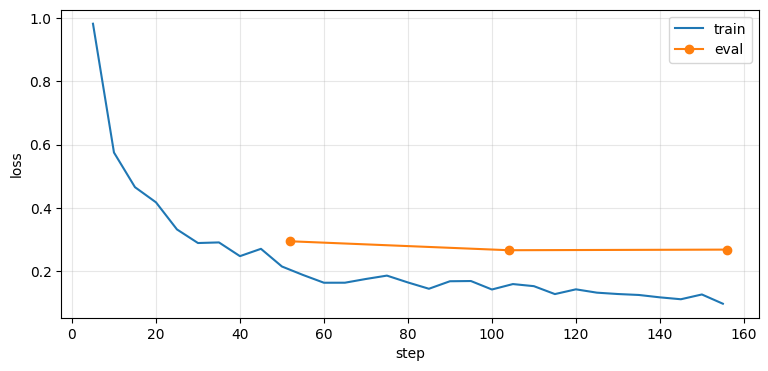

In [13]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Ответ про loss

Здесь loss — cross-entropy только по токенам реплик `assistant`, отмеченным маской
`{% generation %}`. Токены system/user и результаты функций имеют label `-100`, поэтому не входят в
среднее. Потому что модель должна научиться генерировать текст и `<tool_call>`, но не должна угадывать
вопрос пользователя или результат ещё не выполненной функции. Снижение train loss означает, что модель
лучше воспроизводит обучающие ответы.Чтобы не переобучаться, я 
сохраняю checkpoint с минимальным `eval_loss`, но качество function calling дополнительно проверяется
отдельными `tool_set_accuracy` и `exact_match`: низкий language-model loss сам по себе не гарантирует
правильного выбора функции и аргументов.

## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [14]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [15]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()  # trainer мог оставить модель в train-режиме

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
scores = pd.concat([
    summarize(evaluate(base_model, tokenizer, cases)).assign(model="base"),
    summarize(evaluate(model, tokenizer, cases)).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.550
1,base,ru,0.75,0.200
2,sft,en,0.90,0.875
3,sft,ru,0.95,0.900


Те же десять запросов: base-модель и обученная.

In [16]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk""}}\n</tool_call>\n<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""butter""}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,How can I help you today?,Hello! How can I help you?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set the temperature there, add items to your shopping list or start timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>",Which room should I turn it on in?


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [17]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    last_output = ""
    for _ in range(max_steps):
        last_output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(last_output)

        # Невалидный формат или обычный текст: ничего исполнять нельзя.
        if calls is None or not calls:
            messages.append({"role": "assistant", "content": last_output})
            break

        content = TOOL_CALL_PATTERN.sub("", last_output).strip()
        tool_calls = [
            {
                "type": "function",
                "function": {"name": call["name"], "arguments": call["arguments"]},
            }
            for call in calls
        ]
        messages.append({"role": "assistant", "content": content, "tool_calls": tool_calls})

        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool",
                "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })

    return last_output

In [18]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
for prompts in scenarios:
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Make it two degrees warmer in the bedroom.
[assistant] Which degree is the bedroom already at?
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 22})
[tool] {"room": "bedroom", "light": "off", "temperature": 22}
[assistant] The bedroom is now set to 22 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 22}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Thanks!
[assistant] You're welcome! If you have any other questions, feel free to ask.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Open the garage.
[assistant] I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set the temperature there, add items to your shopping list or start timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [19]:
launch_chat(model, tokenizer, SmartHome(), run_agent)